# NAVE for text

`NAVEText` explains a text encoder: one concept per token. Two encoders on **Reuters** news (the five
largest topics):
- spaCy's pretrained `tok2vec`, built into nave-xai, which was trained for tagging and parsing;
- a small topic classifier trained in this notebook with PyTorch.

**Downloads:** Reuters through NLTK (about 2.5 MB) and spaCy's `en_core_web_sm` (about 12 MB, from
GitHub). **Needs:** `pip install "nave-xai[text]" torch nltk`.

In [1]:
# %pip install "nave-xai[text]" torch nltk
import html, re, subprocess, sys
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import nltk, spacy
from nave_xai import NAVEText

nltk.download("reuters", quiet=True)                            # about 2.5 MB
try:
    spacy.load("en_core_web_sm")
except OSError:                                                  # about 12 MB, from GitHub
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=True)
from nltk.corpus import reuters

def clean(text):
    return re.sub(r"\s+", " ", html.unescape(text).replace("<", "").replace(">", "")).strip()

single = [d for d in reuters.fileids() if len(reuters.categories(d)) == 1]
topics = [c for c, _ in Counter(reuters.categories(d)[0] for d in single).most_common(5)]
docs = {"train": [], "test": []}
for d in single:
    c = reuters.categories(d)[0]
    if c in topics:
        docs["train" if d.startswith("training/") else "test"].append((clean(reuters.raw(d)), topics.index(c)))
print(topics, {k: len(v) for k, v in docs.items()})

['earn', 'acq', 'crude', 'trade', 'money-fx'] {'train': 5161, 'test': 2063}


## spaCy's general-purpose encoder

No classes needed: what does an encoder trained for tagging and parsing separate?

In [2]:
rng = np.random.default_rng(0)
sample = [docs["train"][i] for i in rng.choice(len(docs["train"]), 600, replace=False)]
texts, labels = [t for t, _ in sample], np.array([y for _, y in sample])

general = NAVEText("spacy", k=10).fit(texts)
for k in range(10):
    print(k, " ".join(general.words[k]))

0 hong jardine chicago borg jim james
1 france venezuela europe korea britain bundesbank
2 week debt level distribution basis decision
3 barrels businesses nations figures periods credits
4 two three 1985 23 24 70
5 those your an some our every
6 prior fiscal full pretax possible next
7 not also if ' could there
8 . in for with into between
9 said told includes reported include reduce


Its concepts are parts of speech: names, numbers, verbs, prepositions... With the topics as groups
(one projector per topic), the concepts that do relate to topics stand out:

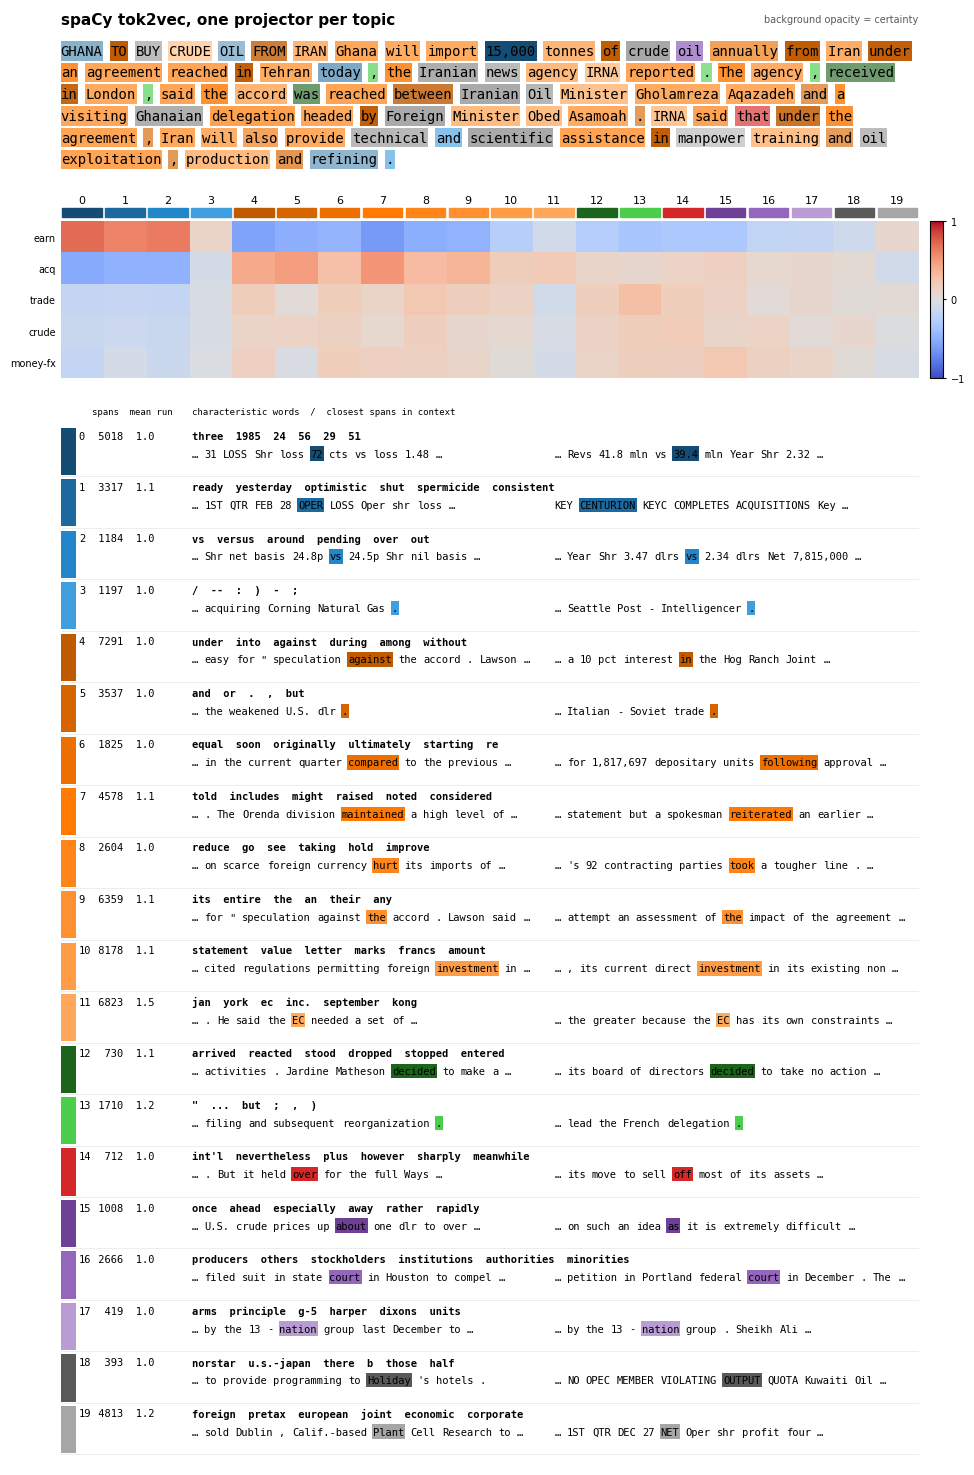

In [3]:
by_topic = NAVEText("spacy", k=4, class_names=topics).fit(texts, groups=labels)
by_topic.reorder(by="classes", recolor=True)
crude = next(t for t, y in docs["test"] if y == topics.index("crude") and len(t) < 700)
by_topic.summarize(crude, title="spaCy tok2vec, one projector per topic");

## A topic classifier

A small text CNN: embeddings, three residual dilated convolutions (each sees a wider context), average
pooling and a linear head. NAVE needs a function from tokens to the blocks' outputs; the class scores,
returned as `"logits"`, give the predicted classes and the saliency.

In [4]:
tokenize = lambda text: re.findall(r"\w+(?:['.-]\w+)*|[^\w\s]", text)
train_tokens = [tokenize(t)[:128] for t, _ in docs["train"]]
vocab = {w: i + 2 for i, (w, _) in enumerate(Counter(t.lower() for d in train_tokens for t in d).most_common(10000))}

def ids(tokens, length=128):
    x = torch.zeros(length, dtype=torch.long)
    v = [vocab.get(t.lower(), 1) for t in tokens[:length]]
    x[:len(v)] = torch.tensor(v, dtype=torch.long)
    return x

class TextCNN(nn.Module):
    def __init__(self, n_classes, dim=96):
        super().__init__()
        self.emb = nn.Embedding(len(vocab) + 2, dim, padding_idx=0)
        self.blocks = nn.ModuleList([nn.Sequential(nn.Conv1d(dim, dim, 3, padding=d, dilation=d), nn.ReLU(),
                                                   nn.Conv1d(dim, dim, 3, padding=d, dilation=d)) for d in (1, 2, 4)])
        self.fc = nn.Linear(dim, n_classes)

    def features(self, x):
        mask = (x > 0).float()[:, None]
        h = self.emb(x).transpose(1, 2) * mask
        outs = []
        for b in self.blocks:
            h = torch.relu(h + b(h)) * mask
            outs.append(h)
        return outs, mask

    def forward(self, x):
        outs, mask = self.features(x)
        return self.fc((outs[-1] * mask).sum(2) / mask.sum(2).clamp(min=1))

torch.manual_seed(0)
clf = TextCNN(len(topics))
X = torch.stack([ids(t) for t in train_tokens]); y = torch.tensor([c for _, c in docs["train"]])
weights = torch.tensor(len(y) / (len(topics) * np.bincount(y.numpy())), dtype=torch.float32)
opt = torch.optim.AdamW(clf.parameters(), 2e-3, weight_decay=1e-4)
for epoch in range(6):
    for batch in torch.randperm(len(y)).split(128):
        loss = nn.functional.cross_entropy(clf(X[batch]), y[batch], weight=weights)
        opt.zero_grad(); loss.backward(); opt.step()
clf.eval()
Xte = torch.stack([ids(tokenize(t)[:128]) for t, _ in docs["test"]])
with torch.no_grad():
    print("test accuracy:", (clf(Xte).argmax(1).numpy() == np.array([c for _, c in docs["test"]])).mean())

test accuracy: 0.9641299079011149


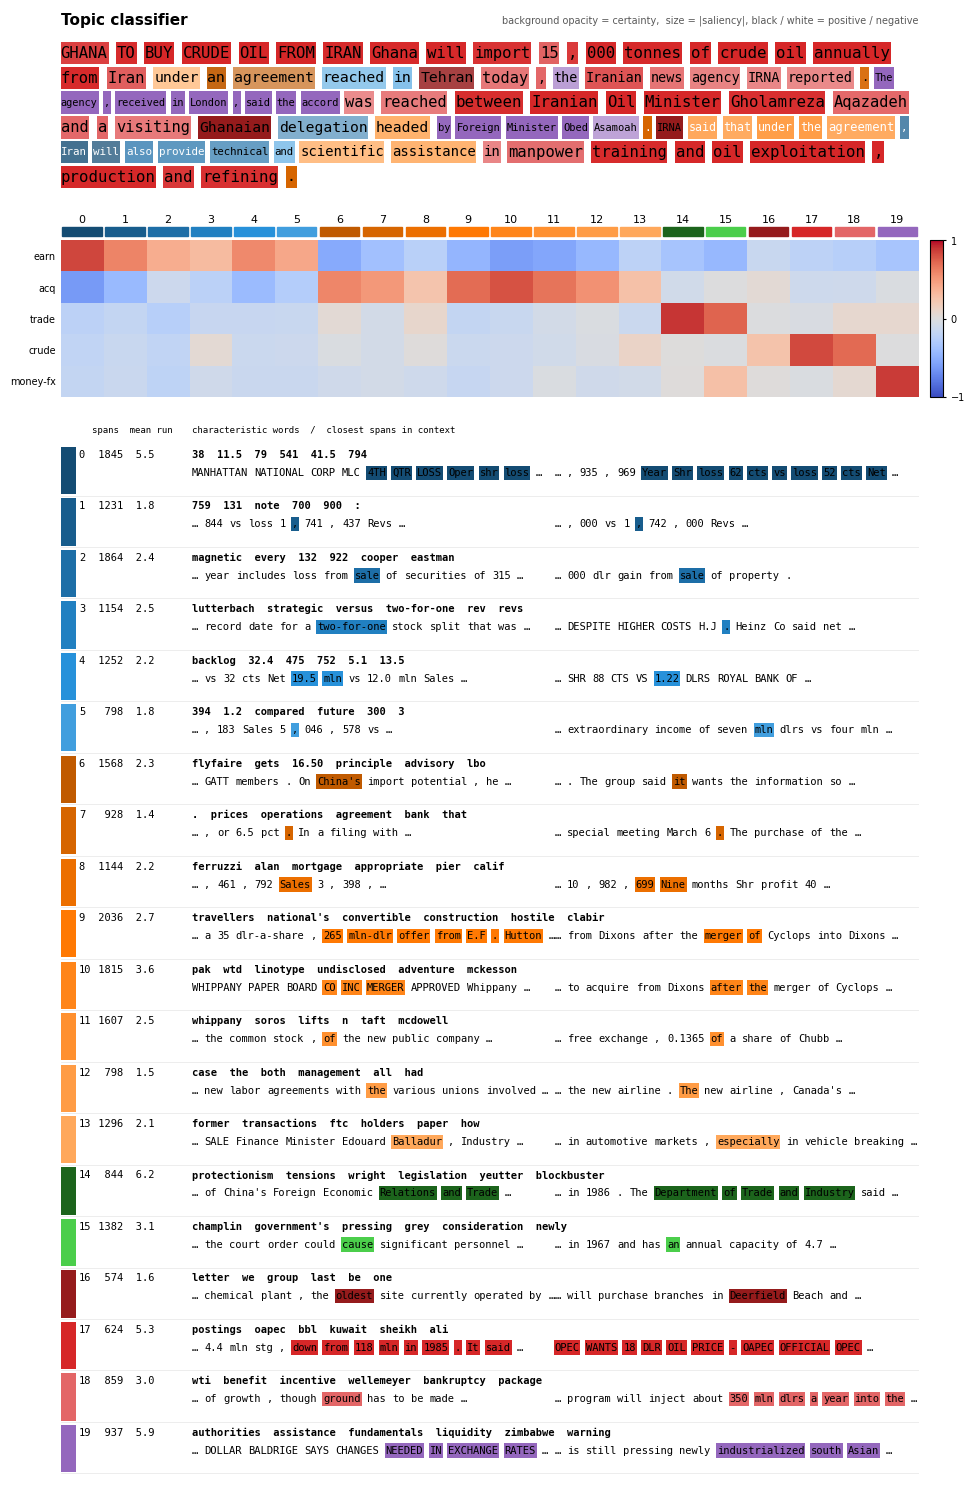

In [5]:
def text_cnn(tokens):
    # tokens -> the three blocks' outputs (96, n) and the class scores
    n = min(len(tokens), 128)
    with torch.no_grad():
        x = ids(tokens)[None]
        outs, _ = clf.features(x)
        logits = clf(x)[0].numpy()
    return {f"block{i + 1}": o[0, :, :n].numpy() for i, o in enumerate(outs)} | {"logits": logits}

topic_explainer = NAVEText(text_cnn, layers=["block1", "block2", "block3"], k=20, tokenizer=tokenize,
                           classifier=clf.fc.weight.detach().numpy(), class_names=topics).fit(texts)
topic_explainer.reorder(by="classes", recolor=True)
topic_explainer.summarize(crude, saliency=True, title="Topic classifier");

Background opacity is the saliency of the predicted topic, and the text fades from black (certain)
to white (uncertain). The concept table gives, for every concept, its correlation with the predicted
topics, its spans, its characteristic words and its closest spans in context.

## Citation

If you use nave-xai, please cite the paper:

```bibtex
@inproceedings{boubekki2026nave,
  author    = {Boubekki, Ahc{\`e}ne and Fadel, Samuel G. and Mair, Sebastian},
  editor    = {Ceci, Michelangelo and Kocev, Dragi and Monreale, Anna and Vens, Celine and Flach, Peter
               and Manco, Giuseppe and Spiliopoulou, Myra and Masciari, Elio},
  title     = {Multi-depth Concept Extraction for Post-Hoc Vision Encoder Explanation},
  booktitle = {Machine Learning and Knowledge Discovery in Databases. Research Track},
  publisher = {Springer Nature Switzerland},
  address   = {Cham},
  pages     = {449--467},
  year      = {2026},
  doi       = {10.1007/978-3-032-37664-0_26},
  isbn      = {978-3-032-37664-0}
}
```